# 7. Visualization: 7-day MrP estimates vs survey targets

Same plots, metrics and file layout as the biweekly `archive/MrP_pipeline/19_new_updated_cleaned_visualization.ipynb`, adapted to the 7-day outputs:

- **MrP side**: `generated_data/mrp_7d/<run>/<belief>/predictions/*_stan_output/` (52 weekly windows, 400 posterior draws each). Only beliefs with `belief_done.ok` are used, so rerun this notebook as more beliefs finish.
- **Target side**: `generated_data/target_df_7d/basic_{gss,anes,cces}_target_df_7d.csv` and `target_map_7d.csv` (all targets, not only the wording source).
- **Matching in time.** The biweekly notebook used one window per survey (the window with the most respondents). With 7-day windows a single week holds only a small part of each survey, so the demographic and state comparisons **pool the MrP draws over the weeks the survey was in the field**: for each subgroup, week *w* gets weight = number of that survey's respondents in that subgroup and week. This is done draw by draw, so the result is still 400 posterior draws. The national-over-time plots compare week by week (weeks with at least `MIN_N_WINDOW` respondents).
- **Survey uncertainty**: unweighted means, 400 bootstrap replicates (the same procedure as before, with as many replicates as posterior draws, so metric CIs match draw *i* with replicate *i*).
- **Wasserstein distance (W)**: a separate metric comparing each subgroup's whole answer distribution, not just its mean. For ordered categories 1..K with spacing 1/(K-1), W = sum over k < K of |F_MrP(k) - F_survey(k)| / (K-1) (F = cumulative distribution), already on the 0-1 scale, so no further normalization. W >= |normalized mean difference|; for K = 2 they are equal. The interval pairs posterior draw *i* with bootstrap replicate *i*, like the other metrics.
- **Cross-target consistency (ceiling)**: every subgroup x survey pair (GSS-ANES, ANES-CCES, CCES-GSS) is a separate data point. All metrics, including W, now have intervals: bootstrap replicate *i* of one survey paired with replicate *i* of the other. The per-belief demographic plots use demographic subgroups only, as the pooled plot does.
- **Not included yet**: the 5 targets that need a conversion on the LLM side (`llm_map` in `target_map_7d.csv`: V241229-CCES, MARSAME-CCES, V242331x-CCES, V242328x-CCES, V241395x-CCES). The category probabilities this notebook now merges into broad groups and national (see *MrP predictions*) are what such a conversion would need.

Outputs (inside the run folder, separate from the biweekly plots):
- `<run>/<belief>/plot/<belief>_demographics.png`, `<belief>_state.png`
- `<run>/all_belief_plots/all_beliefs_demographics.png`, `all_beliefs_state.png`, `plot_df.csv` (with the per-cell `wdist`)
- `<run>/national_plots/national_time_window_scatter.png`, `national_overtime_trend.png`, `national_pooled_vs_obs.png`, `national_time_correlation.csv`

In [1]:
import json
import math
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse, Patch
from scipy import stats
from IPython.display import Image, display, Markdown

# Global font-size scale (Adjust FONT_SCALE to make all text on all plots larger or smaller)
FONT_SCALE = 1.5

GENERATED_DIR = Path(r"D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data")
RUN_NAME = "td10_ad08_w1000_s1000"
PREDICTION_SUBDIR = "predictions"
RUN_DIR = GENERATED_DIR / "mrp_7d" / RUN_NAME
TARGET_DIR = GENERATED_DIR / "target_df_7d"
STRAT_FRAME_CSV = GENERATED_DIR / "feature_extraction" / "state_LP_cleaned_sf.csv"

BELIEFS = None          # None = every belief with belief_done.ok; or a list such as ["GRASS", "CC24_440a"]
N_BOOT = 400            # bootstrap replicates = number of posterior draws
MIN_N_GROUP = 10        # subgroup (demographic / state) survey means need at least this many respondents
MIN_N_WINDOW = 20       # weekly national survey means need at least this many respondents
GROUPING_VARS = ['sex', 'age', 'income', 'eth', 'education', 'vote', 'state']
KEY_COLS = ['grouping_var', 'category', 'question_id', 'benchmark']
LEVELS = [68, 80, 90, 95]
# category probabilities are saved by the fine *_idx groups; each idx level lies in exactly one broad group
IDX_TO_BROAD = {'sex': ('sex_idx', 'sex_broad'), 'age': ('age_idx', 'age_broad'), 'eth': ('eth_idx', 'eth_broad'),
                'income': ('income_idx', 'income_broad'), 'education': ('education_idx', 'education_broad'),
                'vote': ('vote_idx', 'vote_broad')}

In [2]:
def ci(arr, level=95):
    alpha = (100 - level) / 2
    return (float(np.percentile(arr, alpha)), float(np.percentile(arr, 100 - alpha)))

## Beliefs, targets and titles

In [3]:
target_map = pd.read_csv(TARGET_DIR / "target_map_7d.csv")

done = sorted(p.parent.parent.name for p in RUN_DIR.glob(f"*/{PREDICTION_SUBDIR}/belief_done.ok"))
belief_ids = done if BELIEFS is None else [b for b in BELIEFS if b in done]
missing = sorted(set(BELIEFS or []) - set(done))
if missing:
    print("Not finished, skipped:", missing)
print(f"{len(belief_ids)} beliefs with complete predictions:", belief_ids)

# targets that need an LLM-side conversion are left out for now (see the introduction)
llm_map_targets = target_map[target_map['llm_map'].notna()]
print("Left out (need llm_map):", (llm_map_targets['id'] + '-' + llm_map_targets['survey']).tolist())
used_map = target_map[target_map['id'].isin(belief_ids) & target_map['llm_map'].isna()].copy()

# scale (number of categories) per question; every target of a question must share it
K_MAP = used_map.groupby('question_id')['K'].agg(lambda k: k.unique().tolist())
if (K_MAP.str.len() > 1).any():
    raise ValueError(f"Targets with different K for one question: {K_MAP[K_MAP.str.len() > 1]}")
K_MAP = K_MAP.str[0].to_dict()

# plot titles: belief id and its targets, e.g. "V241294x: ANES V241294x / CCES CC24_301"
TITLES = (used_map.sort_values('wording_source', ascending=False)
          .groupby('question_id', sort=False)
          .apply(lambda g: f"{g['id'].iloc[0]}: " + ' / '.join(g['survey'] + ' ' + g['var']), include_groups=False)
          .to_dict())
ID_BY_QUESTION = dict(zip(used_map['question_id'], used_map['id']))
used_map[['id', 'survey', 'benchmark', 'var', 'wave', 'wording_source', 'confidence_low', 'map', 'K']]

40 beliefs with complete predictions: ['ABANY', 'AFFRMACT', 'BIASNEWS', 'CAPPUN', 'CC24_326d', 'CC24_440a', 'CC24_443d', 'CC24_444a', 'CONLABORY', 'COURTS', 'DIVLAW', 'EQWLTH', 'FEFAM', 'FEPOLV', 'GRASS', 'GUNLAW', 'IMMCRIME1', 'IMMFATE', 'IMMJOBS1', 'LETIN1A', 'MARSAME', 'SATDEMOC', 'SMNEWS', 'TEMPGEN1', 'V241129x', 'V241133x', 'V241137x', 'V241229', 'V241294x', 'V241395x', 'V241400x', 'V241403x', 'V241409x', 'V241608', 'V242301', 'V242328x', 'V242331x', 'V242353x', 'V242357x', 'WRKWAYUP']
Left out (need llm_map): ['V241229-CCES', 'MARSAME-CCES', 'V242331x-CCES', 'V242328x-CCES', 'V241395x-CCES']


,id,survey,benchmark,var,wave,wording_source,confidence_low,map,K
0,LETIN1A,GSS,gss,letin1a,single,True,False,NaN,5
1,IMMCRIME1,GSS,gss,immcrime1,single,True,False,NaN,5
2,IMMJOBS1,GSS,gss,immjobs1,single,True,False,NaN,5
3,IMMFATE,GSS,gss,immfate,single,True,False,NaN,3
4,DIVLAW,GSS,gss,divlaw,single,True,False,NaN,3
...,...,...,...,...,...,...,...,...,...
58,CONLABORY,ANES,ANES2024,V242140,post,False,False,"""thermometer""",3
59,BIASNEWS,ANES,ANES2024,V241335,pre,False,False,NaN,5
60,TEMPGEN1,ANES,ANES2024,V242174,post,False,False,NaN,5
61,IMMJOBS1,ANES,ANES2024,V242228,post,False,True,"{""1"": 1, ""2"": 2, ""3"": 4, ""4"": 5}",5


In [4]:
# prediction windows (identical for every belief)
def window_dirs(belief_id):
    question_id = f"Belief_{belief_id}_Symbol"
    folder = RUN_DIR / belief_id / PREDICTION_SUBDIR
    return {p.name.removeprefix(f"{question_id}_").removesuffix("_stan_output"): p
            for p in sorted(folder.glob(f"{question_id}_*_stan_output"))}

WINDOWS = list(window_dirs(belief_ids[0]))
print(f"{len(WINDOWS)} prediction windows: {WINDOWS[0]} ... {WINDOWS[-1]}")


# helper function to parse time_window_bin labels like '[2024-08-11 , 2024-08-18)' to get the start date for matching
def parse_time_window_start(bin_label):
    return str(bin_label).strip().lstrip('[').split(',')[0].strip()

52 prediction windows: 2023-11-05 ... 2024-10-27


In [5]:
# load the target dataframes (each row is an observation from an individual with a specific belief value for one question)
df_obs = pd.concat([pd.read_csv(TARGET_DIR / f"basic_{s}_target_df_7d.csv", low_memory=False)
                    for s in ['anes', 'gss', 'cces']], ignore_index=True)
df_obs = df_obs.merge(used_map[['question_id', 'benchmark']], on=['question_id', 'benchmark'], how='inner')
df_obs = df_obs[df_obs['belief_value'].notna() & (df_obs['belief_value'] >= 0)].copy()
df_obs['time_window_bin'] = df_obs['time_window_bin'].astype(str)
df_obs['window_start'] = df_obs['time_window_bin'].map(parse_time_window_start)
outside = ~df_obs['window_start'].isin(WINDOWS)
print(f"{outside.sum()} of {len(df_obs)} target rows fall outside the prediction windows and are dropped")
df_obs = df_obs[~outside].copy()
df_obs['national'] = 'national'   # pooled national category
df_obs.groupby(['question_id', 'benchmark']).agg(n=('belief_value', 'size'), weeks=('window_start', 'nunique'),
                                                 mean=('belief_value', 'mean'))

5450 of 821674 target rows fall outside the prediction windows and are dropped


n  weeks      mean
question_id            benchmark                        
Belief_ABANY_Symbol    ANES2024    4216     14  1.348197
                       CCES2024   59961      5  1.348927
                       gss         1925     31  1.396883
Belief_AFFRMACT_Symbol ANES2024    4743     14  2.947712
                       gss         1806     31  2.984496
...                                 ...    ...       ...
Belief_V242353x_Symbol ANES2024    4634     14  3.017911
Belief_V242357x_Symbol ANES2024    4813     14  2.625597
Belief_WRKWAYUP_Symbol ANES2024    4641     14  2.854126
                       CCES2024   49422      5  2.800615
                       gss         1917     31  2.703182

[63 rows x 3 columns]

## MrP predictions

For each belief, read every window's group draws (`group_<var>_all_draws.csv`) and national draws. Then for each target survey:
- subgroup rows (`grouping_var` = sex, age, ..., state, and `national`): draws pooled over the survey's weeks, weighted by the survey's respondents in that subgroup and week;
- `time_window_bin` rows: the national draws of that week (one row per week the survey has respondents).

The category probability draws (`group_<var>_category_all_draws.csv`, for the Wasserstein distance) are read the same way. The pipeline saves them by the fine `*_idx` groups (and by state). Each idx level lies in exactly one broad group, so a broad group's probabilities are the population-weighted mean of its idx levels, using each posterior draw's own population draw (`draw_plan.csv`, `N_star.<j>`): the same poststratification as the pipeline. National comes from the two `sex_idx` groups. The loader checks that sum_k k * p_k reproduces the saved expected-value draws.

In [6]:
# Population of each fine *_idx level under every population draw N_star.<j>, used to merge the saved
# idx-level category probabilities into the broad groups exactly as the pipeline poststratifies
idx_cols = [c for pair in IDX_TO_BROAD.values() for c in pair]
strat = pd.read_csv(STRAT_FRAME_CSV, usecols=lambda c: c in idx_cols or (c.startswith('N_star.') and c[7:].isdigit()))
n_star_cols = [c for c in strat.columns if c.startswith('N_star.')]
IDX_POP, IDX_BROAD = {}, {}
for gvar, (idx_col, broad_col) in IDX_TO_BROAD.items():
    nesting = strat[[idx_col, broad_col]].drop_duplicates()
    if nesting[idx_col].duplicated().any():
        raise ValueError(f"{idx_col} levels are not nested in {broad_col}")
    IDX_BROAD[gvar] = nesting.set_index(idx_col)[broad_col].astype(str)
    IDX_POP[gvar] = strat.groupby(idx_col)[n_star_cols].sum()   # (idx levels, population draws)
del strat
print(f"{len(n_star_cols)} population draws")
{gvar: s.to_dict() for gvar, s in IDX_BROAD.items()}

104 population draws


{'sex': {2: 'Female', 1: 'Male'},
 'age': {1: '18-34', 2: '18-34', 3: '35-54', 4: '35-54', 5: '55+', 6: '55+'},
 'eth': {4: 'Non-white',
  2: 'Non-white',
  3: 'Non-white',
  6: 'Non-white',
  5: 'Non-white',
  1: 'White'},
 'income': {1: '<50k', 2: '<50k', 3: '50-100k', 4: '50-100k', 5: '100k+'},
 'education': {1: 'Non-college', 2: 'College'},
 'vote': {1: 'StayHome',
  2: 'Republican',
  3: 'Democratic',
  4: 'Other',
  6: 'Other',
  5: 'Other'}}

In [7]:
def load_window_draws(belief_id):
    """One belief, windows in WINDOWS order. Returns
    - {(grouping_var, category): array (n_windows, n_draws)}: expected-value draws as saved by the pipeline;
    - {(grouping_var, category): array (n_windows, K-1, n_draws)}: cumulative category probabilities P(y <= k), k < K;
    - draw_cols.
    Category draws are saved by the fine *_idx groups (and by state); idx groups are merged into the broad groups
    (and sex_idx into national) with each draw's own population draw, then checked against the expected values.
    """
    dirs = window_dirs(belief_id)
    if list(dirs) != WINDOWS:
        raise ValueError(f"{belief_id}: prediction windows differ from {belief_ids[0]}")
    K = K_MAP[f"Belief_{belief_id}_Symbol"]
    k_values = np.arange(1, K + 1)[:, None]
    plan = pd.read_csv(RUN_DIR / belief_id / PREDICTION_SUBDIR / 'draw_plan.csv').set_index('draw_col')['weight_col']
    per_window, per_window_cdf, pop, worst = [], [], None, 0.0
    for window, d in dirs.items():
        frames = []
        for gvar in GROUPING_VARS:
            g = pd.read_csv(d / f"group_{gvar}_all_draws.csv")   # first column = group label, then draw_1 ... draw_N
            g.index = pd.MultiIndex.from_arrays([[gvar] * len(g), g.iloc[:, 0].astype(str)], names=['grouping_var', 'category'])
            frames.append(g.iloc[:, 1:])
        draw_cols = list(frames[0].columns)
        nat = pd.read_csv(d / "national_all_draws.csv")         # long format: one row per draw
        frames.append(pd.DataFrame([nat['expected_value'].to_numpy()], columns=draw_cols,
                                   index=pd.MultiIndex.from_tuples([('national', 'national')], names=['grouping_var', 'category'])))
        ev = pd.concat(frames)
        per_window.append(ev)

        if pop is None:   # population of every idx level under each draw's own population draw: (idx levels, draws)
            pop = {gvar: IDX_POP[gvar][plan.loc[draw_cols].tolist()] for gvar in IDX_TO_BROAD}
        probs = {}
        for gvar in GROUPING_VARS:
            c = pd.read_csv(d / f"group_{gvar}_category_all_draws.csv")   # rows (group, category), then draw columns
            group_col = c.columns[0]
            c = c.sort_values([group_col, 'category'])
            groups = c[group_col].drop_duplicates().to_numpy()
            if c['category'].max() != K or len(c) != len(groups) * K:
                raise ValueError(f"{belief_id} {window} {gvar}: expected {K} categories for every group")
            p = c[draw_cols].to_numpy(float).reshape(len(groups), K, len(draw_cols))
            if gvar == 'state':
                probs.update({('state', str(s)): p[i] for i, s in enumerate(groups)})
                continue
            w = pop[gvar].loc[groups].to_numpy(float)
            broad = IDX_BROAD[gvar].loc[groups].to_numpy()
            for b in np.unique(broad):
                m = broad == b
                probs[(gvar, str(b))] = (w[m][:, None, :] * p[m]).sum(axis=0) / w[m].sum(axis=0)
            if gvar == 'sex':
                probs[('national', 'national')] = (w[:, None, :] * p).sum(axis=0) / w.sum(axis=0)
        # exactness check: sum_k k * p_k must reproduce the saved expected-value draws
        for key, p in probs.items():
            worst = max(worst, float(np.abs((k_values * p).sum(axis=0) - ev.loc[key, draw_cols].to_numpy(float)).max()))
        per_window_cdf.append({key: np.cumsum(p, axis=0)[:K - 1] for key, p in probs.items()})
    if worst > 1e-6:
        raise ValueError(f"{belief_id}: merged category probabilities do not reproduce the expected values (max diff {worst:.2e})")
    keys = per_window[0].index
    stacked = np.stack([w.loc[keys, draw_cols].to_numpy(float) for w in per_window], axis=1)  # (keys, windows, draws)
    cdf = {key: np.stack([w[key] for w in per_window_cdf]) for key in per_window_cdf[0]}     # (windows, K-1, draws)
    return {key: stacked[i] for i, key in enumerate(keys)}, cdf, draw_cols, worst


def summarize_draws(draws):
    """Summary columns as in the prediction files, from an array (rows, draws)."""
    out = {'pred_mean': draws.mean(axis=1), 'pred_median': np.median(draws, axis=1), 'pred_sd': draws.std(axis=1, ddof=1)}
    for lv in LEVELS:
        a = (100 - lv) / 2
        out[f'pred_lower_{lv}'] = np.percentile(draws, a, axis=1)
        out[f'pred_upper_{lv}'] = np.percentile(draws, 100 - a, axis=1)
    return pd.DataFrame(out)


llm_parts, llm_draws_parts, national_series_parts = [], [], []
PRED_CDF = {}   # (grouping_var, category, question_id, benchmark) -> MrP cumulative category probabilities (K-1, draws)
for belief_id in belief_ids:
    window_draws, window_cdf, draw_cols, worst = load_window_draws(belief_id)
    question_id = f"Belief_{belief_id}_Symbol"
    nat = window_draws[('national', 'national')]
    national_series_parts.append(summarize_draws(nat).assign(question_id=question_id, window_start=WINDOWS))

    for benchmark, obs in df_obs[df_obs['question_id'] == question_id].groupby('benchmark'):
        keys, rows = [], []
        # subgroups and pooled national: weight each week by this survey's respondents in the subgroup
        for gvar in ['national'] + GROUPING_VARS:
            counts = obs.dropna(subset=[gvar]).groupby([gvar, 'window_start']).size()
            for category, by_week in counts.groupby(level=0):
                if (gvar, str(category)) not in window_draws:
                    raise KeyError(f"{question_id} {benchmark}: no MrP group {gvar}={category}")
                weights = np.zeros(len(WINDOWS))
                weights[[WINDOWS.index(w) for w in by_week.index.get_level_values(1)]] = by_week.to_numpy()
                rows.append(weights @ window_draws[(gvar, str(category))] / weights.sum())
                keys.append((gvar, str(category)))
                PRED_CDF[(gvar, str(category), question_id, benchmark)] = (
                    np.tensordot(weights, window_cdf[(gvar, str(category))], axes=1) / weights.sum())
        # national draws of each week the survey was in the field
        for time_window_bin, window_start in obs[['time_window_bin', 'window_start']].drop_duplicates().itertuples(index=False):
            rows.append(nat[WINDOWS.index(window_start)])
            keys.append(('time_window_bin', time_window_bin))
            PRED_CDF[('time_window_bin', time_window_bin, question_id, benchmark)] = (
                window_cdf[('national', 'national')][WINDOWS.index(window_start)])
        key_df = pd.DataFrame(keys, columns=['grouping_var', 'category']).assign(question_id=question_id, benchmark=benchmark)
        draws = np.vstack(rows)
        llm_parts.append(pd.concat([key_df, summarize_draws(draws)], axis=1))
        llm_draws_parts.append(pd.concat([key_df, pd.DataFrame(draws, columns=draw_cols)], axis=1))
    print(f"{belief_id}: loaded {len(WINDOWS)} windows (category check: max diff {worst:.1e})")

llm_df = pd.concat(llm_parts, ignore_index=True)
# llm_df rows: one row per subgroup x question_id x benchmark, columns: KEY_COLS + pred_mean, pred_median, pred_sd, pred_lower/upper_{68,80,90,95}
llm_draws_df = pd.concat(llm_draws_parts, ignore_index=True)
# llm_draws_df rows: same keys, columns: KEY_COLS + draw_1 ... draw_400
national_series = pd.concat(national_series_parts, ignore_index=True)
# national_series: MrP national estimate for every belief and every week (for the over-time plot)
llm_df.groupby(['question_id', 'benchmark', 'grouping_var']).size().unstack(fill_value=0)

ABANY: loaded 52 windows (category check: max diff 1.1e-09)
AFFRMACT: loaded 52 windows (category check: max diff 1.3e-09)
BIASNEWS: loaded 52 windows (category check: max diff 1.2e-09)
CAPPUN: loaded 52 windows (category check: max diff 1.3e-09)
CC24_326d: loaded 52 windows (category check: max diff 1.3e-09)
CC24_440a: loaded 52 windows (category check: max diff 1.4e-09)
CC24_443d: loaded 52 windows (category check: max diff 1.4e-09)
CC24_444a: loaded 52 windows (category check: max diff 1.2e-09)
CONLABORY: loaded 52 windows (category check: max diff 1.4e-09)
COURTS: loaded 52 windows (category check: max diff 1.4e-09)
DIVLAW: loaded 52 windows (category check: max diff 1.2e-09)
EQWLTH: loaded 52 windows (category check: max diff 1.4e-09)
FEFAM: loaded 52 windows (category check: max diff 1.2e-09)
FEPOLV: loaded 52 windows (category check: max diff 1.3e-09)
GRASS: loaded 52 windows (category check: max diff 1.2e-09)
GUNLAW: loaded 52 windows (category check: max diff 1.3e-09)
IMMCRIME

grouping_var                      age  education  eth  income  national  sex  \
question_id            benchmark                                               
Belief_ABANY_Symbol    ANES2024     3          2    2       3         1    2   
                       CCES2024     3          2    2       3         1    2   
                       gss          3          2    2       3         1    2   
Belief_AFFRMACT_Symbol ANES2024     3          2    2       3         1    2   
                       gss          3          2    2       3         1    2   
...                               ...        ...  ...     ...       ...  ...   
Belief_V242353x_Symbol ANES2024     3          2    2       3         1    2   
Belief_V242357x_Symbol ANES2024     3          2    2       3         1    2   
Belief_WRKWAYUP_Symbol ANES2024     3          2    2       3         1    2   
                       CCES2024     3          2    2       3         1    2   
                       gss          3          2    2       3         1    2   

grouping_var                      state  time_window_bin  vote  
question_id            benchmark                                
Belief_ABANY_Symbol    ANES2024      51               14     4  
                       CCES2024      51                5     4  
                       gss            0               31     4  
Belief_AFFRMACT_Symbol ANES2024      51               14     4  
                       gss            0               31     4  
...                                 ...              ...   ...  
Belief_V242353x_Symbol ANES2024      51               14     4  
Belief_V242357x_Symbol ANES2024      51               14     4  
Belief_WRKWAYUP_Symbol ANES2024      51               14     4  
                       CCES2024      51                5     4  
                       gss            0               31     4  

[63 rows x 9 columns]

## Survey targets with bootstrap CIs

In [8]:
# Aggregate df_obs to subgroup means and CI bands from bootstrap means
def build_bootstrap_target_df(df_obs, n_boot=N_BOOT, seed=42):
    """
    Bootstrap method (as in the biweekly notebook):
    1) For each (question_id, benchmark), bootstrap the full target sample rows.
    2) Within each bootstrap replicate, compute subgroup means (and subgroup answer distributions, for the
       Wasserstein distance).
    3) Compute subgroup intervals from quantiles across replicate means.
    Subgroup means and category counts are computed with np.bincount, so this is fast on the large CCES samples.
    Also returns obs_cdf: {(grouping_var, category, question_id, benchmark): (cumulative answer shares of the full
    sample (K-1,), of every replicate (n_boot, K-1))}, NaN for replicates without respondents in the subgroup.
    """
    rng = np.random.default_rng(seed)  # random number generator for reproducibility
    group_cols = ['national'] + GROUPING_VARS + ['time_window_bin']
    agg_rows, boot_rows, obs_cdf = [], [], {}
    for (qid, bench), subset in df_obs.groupby(['question_id', 'benchmark']):
        y = subset['belief_value'].to_numpy(float)
        n = len(y)
        K = K_MAP[qid]
        y_cat = y.astype(int) - 1   # answer category 0..K-1
        if not (np.array_equal(y_cat + 1, y) and y_cat.min() >= 0 and y_cat.max() < K):
            raise ValueError(f"{qid} {bench}: survey answers are not integers in 1..{K}")
        codes = {}
        for gvar in group_cols:
            c, labels = pd.factorize(subset[gvar])   # missing -> -1
            codes[gvar] = (c, labels)
        boot = {gvar: np.full((n_boot, len(labels)), np.nan) for gvar, (c, labels) in codes.items()}
        boot_cdf = {gvar: np.full((n_boot, len(labels), K - 1), np.nan) for gvar, (c, labels) in codes.items()}
        for draw_idx in range(n_boot):
            sample_idx = rng.integers(0, n, size=n)  # sample with replacement
            ys = y[sample_idx]
            ys_cat = y_cat[sample_idx]
            for gvar, (c, labels) in codes.items():
                cs = c[sample_idx]
                keep = cs >= 0
                total = np.bincount(cs[keep], weights=ys[keep], minlength=len(labels))
                count = np.bincount(cs[keep], minlength=len(labels))
                cat_count = np.bincount(cs[keep] * K + ys_cat[keep], minlength=len(labels) * K).reshape(len(labels), K)
                with np.errstate(invalid='ignore', divide='ignore'):
                    boot[gvar][draw_idx] = total / count
                    boot_cdf[gvar][draw_idx] = np.cumsum(cat_count, axis=1)[:, :K - 1] / count[:, None]
        for gvar, (c, labels) in codes.items():
            keep = c >= 0
            count = np.bincount(c[keep], minlength=len(labels))
            mean = np.bincount(c[keep], weights=y[keep], minlength=len(labels)) / np.maximum(count, 1)
            cat_count = np.bincount(c[keep] * K + y_cat[keep], minlength=len(labels) * K).reshape(len(labels), K)
            cdf = np.cumsum(cat_count, axis=1)[:, :K - 1] / np.maximum(count, 1)[:, None]
            for j, category in enumerate(labels):
                arr = boot[gvar][:, j]
                arr = arr[~np.isnan(arr)]
                row = {'grouping_var': gvar, 'category': str(category), 'question_id': qid, 'benchmark': bench,
                       'n': int(count[j]), 'obs_mean': float(mean[j])}
                for lv in LEVELS:
                    row[f'obs_lower_{lv}'], row[f'obs_upper_{lv}'] = ci(arr, lv)
                agg_rows.append(row)
                ok = ~np.isnan(boot[gvar][:, j])
                boot_rows.append(pd.DataFrame({'grouping_var': gvar, 'category': str(category), 'question_id': qid,
                                               'benchmark': bench, 'draw_idx': np.flatnonzero(ok),
                                               'obs_boot_mean': boot[gvar][ok, j]}))
                obs_cdf[(gvar, str(category), qid, bench)] = (cdf[j], boot_cdf[gvar][:, j, :])
    agg_target_df = pd.DataFrame(agg_rows)
    # row = one subgroup x one question_id x benchmark, columns = KEY_COLS + n, obs_mean, obs_lower/upper_{68,80,90,95}
    target_boot_df = pd.concat(boot_rows, ignore_index=True)
    # row = one subgroup x one question_id x benchmark x one bootstrap replicate, columns = KEY_COLS + draw_idx, obs_boot_mean
    return agg_target_df, target_boot_df, obs_cdf


agg_target_df, target_boot_df, OBS_CDF = build_bootstrap_target_df(df_obs)
# drop survey means from too few respondents
min_n = np.where(agg_target_df['grouping_var'] == 'time_window_bin', MIN_N_WINDOW, MIN_N_GROUP)
print(f"Dropped {(agg_target_df['n'] < min_n).sum()} survey means with too few respondents")
agg_target_df = agg_target_df[agg_target_df['n'] >= min_n].reset_index(drop=True)
agg_target_df.groupby(['question_id', 'benchmark', 'grouping_var']).size().unstack(fill_value=0)

Dropped 284 survey means with too few respondents


grouping_var                      age  education  eth  income  national  sex  \
question_id            benchmark                                               
Belief_ABANY_Symbol    ANES2024     3          2    2       3         1    2   
                       CCES2024     3          2    2       3         1    2   
                       gss          3          2    2       3         1    2   
Belief_AFFRMACT_Symbol ANES2024     3          2    2       3         1    2   
                       gss          3          2    2       3         1    2   
...                               ...        ...  ...     ...       ...  ...   
Belief_V242353x_Symbol ANES2024     3          2    2       3         1    2   
Belief_V242357x_Symbol ANES2024     3          2    2       3         1    2   
Belief_WRKWAYUP_Symbol ANES2024     3          2    2       3         1    2   
                       CCES2024     3          2    2       3         1    2   
                       gss          3          2    2       3         1    2   

grouping_var                      state  time_window_bin  vote  
question_id            benchmark                                
Belief_ABANY_Symbol    ANES2024      47               13     4  
                       CCES2024      51                5     4  
                       gss            0               30     4  
Belief_AFFRMACT_Symbol ANES2024      46               13     4  
                       gss            0               30     4  
...                                 ...              ...   ...  
Belief_V242353x_Symbol ANES2024      46               13     4  
Belief_V242357x_Symbol ANES2024      46               13     4  
Belief_WRKWAYUP_Symbol ANES2024      46               13     4  
                       CCES2024      51                5     4  
                       gss            0               30     4  

[63 rows x 9 columns]

In [9]:
# Merge LLM predictions with aggregated survey observations
def build_plot_df(llm_df, agg_target_df):
    merged = agg_target_df.merge(llm_df, on=KEY_COLS, how='inner')
    # every survey mean must have its MrP counterpart
    if len(merged) != len(agg_target_df):
        lost = agg_target_df.merge(llm_df[KEY_COLS], on=KEY_COLS, how='left', indicator=True)
        raise ValueError(f"Survey rows without MrP prediction:\n{lost[lost['_merge'] == 'left_only'][KEY_COLS]}")
    return merged


plot_df = build_plot_df(llm_df, agg_target_df)
# count the number of targets per question_id
counts = (plot_df
          .groupby(['question_id', 'grouping_var', 'category'])['benchmark']
          .nunique()
          .rename('n_obs_sources')
          .reset_index())
plot_df = plot_df.merge(counts, on=['question_id', 'grouping_var', 'category'])
plot_df['has_multiple_obs'] = plot_df['n_obs_sources'] > 1
plot_df.head()

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_lower_68,pred_upper_68,pred_lower_80,pred_upper_80,pred_lower_90,pred_upper_90,pred_lower_95,pred_upper_95,n_obs_sources,has_multiple_obs
0,national,national,Belief_ABANY_Symbol,ANES2024,4216,1.348197,1.341518,1.356025,1.339184,1.358444,...,1.423546,1.439804,1.421159,1.441776,1.418103,1.444429,1.415305,1.447242,3,True
1,sex,Female,Belief_ABANY_Symbol,ANES2024,2281,1.313897,1.305897,1.323237,1.303555,1.325844,...,1.381118,1.400738,1.377436,1.403327,1.374546,1.406753,1.370956,1.409707,3,True
2,sex,Male,Belief_ABANY_Symbol,ANES2024,1905,1.388451,1.376142,1.399055,1.371859,1.402458,...,1.465167,1.484862,1.461731,1.487871,1.459175,1.490617,1.456254,1.493352,3,True
3,age,35-54,Belief_ABANY_Symbol,ANES2024,1327,1.311982,1.300207,1.324778,1.296610,1.327814,...,1.384485,1.404907,1.381215,1.407223,1.377565,1.411584,1.374223,1.415614,3,True
4,age,55+,Belief_ABANY_Symbol,ANES2024,1977,1.391502,1.380941,1.401475,1.378221,1.404435,...,1.518743,1.540836,1.516707,1.543965,1.511621,1.547121,1.507349,1.550768,3,True


In [10]:
# Wasserstein (earth mover's) distance between the MrP and survey answer distributions of each cell.
# Ordered categories 1..K with spacing 1/(K-1): W = sum_{k<K} |F_pred(k) - F_obs(k)| / (K-1), with F the cumulative
# distribution, so W is already on the 0-1 scale (no further normalization). W >= |normalized mean difference|;
# for K = 2 the two are equal.
def wasserstein_ordinal(cdf_a, cdf_b):
    """cdf arrays (..., K-1) -> W (...)"""
    return np.abs(cdf_a - cdf_b).sum(axis=-1) / cdf_a.shape[-1]


w_point, w_parts = [], []
for row in plot_df[KEY_COLS].itertuples(index=False):
    key = (row.grouping_var, row.category, row.question_id, row.benchmark)
    pred = PRED_CDF[key].T                 # (draws, K-1)
    obs_point, obs_boot = OBS_CDF[key]     # (K-1,), (n_boot, K-1)
    if len(pred) != len(obs_boot):
        raise ValueError(f"{key}: {len(pred)} posterior draws but {len(obs_boot)} bootstrap replicates")
    w_point.append(wasserstein_ordinal(pred.mean(axis=0), obs_point))
    w = wasserstein_ordinal(pred, obs_boot)   # posterior draw i vs bootstrap replicate i
    ok = ~np.isnan(w)
    w_parts.append(pd.DataFrame({'grouping_var': row.grouping_var, 'category': row.category,
                                 'question_id': row.question_id, 'benchmark': row.benchmark,
                                 'draw_idx': np.flatnonzero(ok), 'w_draw': w[ok]}))
plot_df['wdist'] = w_point
wdist_draws_df = pd.concat(w_parts, ignore_index=True)
# wdist_draws_df rows: one subgroup x question_id x benchmark x draw index, columns = KEY_COLS + draw_idx, w_draw
(RUN_DIR / 'all_belief_plots').mkdir(parents=True, exist_ok=True)
plot_df.to_csv(RUN_DIR / 'all_belief_plots' / 'plot_df.csv', index=False)
plot_df.groupby(['question_id', 'grouping_var'])['wdist'].mean().unstack().round(3)

grouping_var,age,education,eth,income,national,sex,state,time_window_bin,vote
question_id,,,,,,,,,
Belief_ABANY_Symbol,0.071,0.055,0.067,0.072,0.063,0.063,0.119,0.065,0.131
Belief_AFFRMACT_Symbol,0.070,0.066,0.081,0.067,0.067,0.065,0.091,0.082,0.104
Belief_BIASNEWS_Symbol,0.143,0.143,0.150,0.146,0.142,0.145,0.216,0.125,0.137
Belief_CAPPUN_Symbol,0.151,0.154,0.162,0.147,0.144,0.146,0.152,0.134,0.190
Belief_CC24_326d_Symbol,0.108,0.124,0.157,0.118,0.125,0.128,0.135,0.126,0.148
Belief_CC24_440a_Symbol,0.076,0.064,0.072,0.071,0.068,0.068,0.085,0.072,0.080
Belief_CC24_443d_Symbol,0.087,0.105,0.117,0.099,0.102,0.104,0.108,0.104,0.141
Belief_CC24_444a_Symbol,0.327,0.333,0.346,0.328,0.333,0.336,0.327,0.331,0.388
Belief_CONLABORY_Symbol,0.218,0.211,0.210,0.216,0.214,0.222,0.300,0.198,0.213


## Metrics and plotting functions (from the biweekly notebook)

In [11]:
# Compute normalized bias, normalized RMSE, correlation, 95% coverage and Wasserstein distance for both the point
# estimates and the draw-level distributions
def compute_metrics(plot_df, llm_draws_df, target_boot_df, wdist_draws_df, question_id=None, y_range=None):
    """
    CI logic:
    - Prediction uncertainty from posterior draws (llm_draws_df)
    - Target uncertainty from bootstrap means (target_boot_df)
    - For each subgroup cell, match draw i with draw i, then pool across all cells to build metric distributions.
    - Wasserstein distance: per-cell W of posterior draw i vs bootstrap replicate i (wdist_draws_df), averaged over
      cells for each i. W is already on the 0-1 scale, so it is not divided by y_range.
    """
    draw_cols = [c for c in llm_draws_df.columns if c not in set(KEY_COLS)]

    # convert llm_draws_df from wide to long format, so that each row is one subgroup x one question_id x benchmark x one draw combination
    pred_long = llm_draws_df.melt(id_vars=KEY_COLS, value_vars=draw_cols, value_name='pred_draw')
    pred_long['draw_idx'] = pred_long.groupby(KEY_COLS).cumcount()

    # Reuse the prediction intervals already present in plot_df.
    pred_ci = plot_df[KEY_COLS + ['pred_lower_95', 'pred_upper_95']]
    targ_long = target_boot_df.rename(columns={'obs_boot_mean': 'obs_draw'})
    matched = pred_long.merge(targ_long[KEY_COLS + ['draw_idx', 'obs_draw']], on=KEY_COLS + ['draw_idx'], how='inner'
                              ).merge(pred_ci, on=KEY_COLS, how='left')

    if y_range is None:
        y_range = K_MAP[question_id] - 1

    def point_metrics(x, y):
        bias = np.mean(np.abs(x - y))
        rmse = np.sqrt(np.mean((x - y) ** 2))
        corr, _ = stats.spearmanr(x, y)
        return bias / y_range, rmse / y_range, corr

    # Point metrics from means shown in the scatter plot.
    x0 = plot_df['pred_mean'].to_numpy(dtype=float)
    y0 = plot_df['obs_mean'].to_numpy(dtype=float)
    nbias0, nrmse0, corr0 = point_metrics(x0, y0)
    cov0 = np.mean((plot_df['pred_lower_95'].to_numpy(dtype=float) <= y0) & (y0 <= plot_df['pred_upper_95'].to_numpy(dtype=float)))
    w0 = float(plot_df['wdist'].mean())

    # Metric distributions across matched draw index.
    metric_by_draw = []
    for d, grp in matched.groupby('draw_idx', sort=True):
        x = grp['pred_draw'].to_numpy(dtype=float)
        y = grp['obs_draw'].to_numpy(dtype=float)
        b, r, c = point_metrics(x, y)
        cv = np.mean((grp['pred_lower_95'].to_numpy(dtype=float) <= y) & (y <= grp['pred_upper_95'].to_numpy(dtype=float)))
        metric_by_draw.append((b, r, c, cv))
    metric_arr = np.array(metric_by_draw, dtype=float)  # shape = (n_draws, 4), columns = ['nbias', 'nrmse', 'corr', 'coverage']
    w_by_draw = wdist_draws_df.groupby('draw_idx')['w_draw'].mean().to_numpy()

    return {
        'bias_mean': float(nbias0), 'bias_ci': ci(metric_arr[:, 0]),
        'rmse_mean': float(nrmse0), 'rmse_ci': ci(metric_arr[:, 1]),
        'corr_mean': float(corr0), 'corr_ci': ci(metric_arr[:, 2]),
        'coverage_mean': float(cov0), 'coverage_ci': ci(metric_arr[:, 3]),
        'wdist_mean': w0, 'wdist_ci': ci(w_by_draw),
        'n_cells': int(matched[KEY_COLS].drop_duplicates().shape[0]),
    }


def subset_draws(rows, llm_draws_input, target_boot_input, wdist_input=None):
    """Draw-level inputs (MrP draws, bootstrap means, Wasserstein draws) restricted to the cells in `rows`."""
    keys = rows[KEY_COLS].drop_duplicates()
    wdist_input = wdist_draws_df if wdist_input is None else wdist_input   # W does not depend on standardization
    return (llm_draws_input.merge(keys, on=KEY_COLS, how='inner'),
            target_boot_input.merge(keys, on=KEY_COLS, how='inner'),
            wdist_input.merge(keys, on=KEY_COLS, how='inner'))

In [12]:
# build a dataframe for pairwise comparison of observation sources, where each row is one subgroup x question_id
# x benchmark pair (GSS-ANES, ANES-CCES, CCES-GSS): every pair is a separate data point
def compute_obs_pairwise(plot_df):
    multi = plot_df[plot_df['has_multiple_obs']].copy()
    if multi.empty:
        return pd.DataFrame()
    pairwise_records = []
    for (ds_a, ds_b) in combinations(sorted(multi['benchmark'].unique()), 2):  # each pair of observation sources
        df_a = multi[multi['benchmark'] == ds_a].set_index(['question_id', 'grouping_var', 'category'])
        df_b = multi[multi['benchmark'] == ds_b].set_index(['question_id', 'grouping_var', 'category'])
        shared_idx = df_a.index.intersection(df_b.index)  # align on shared cells
        if len(shared_idx) == 0:
            continue
        pairwise_records.append(pd.DataFrame({
            'question_id': [i[0] for i in shared_idx],
            'grouping_var': [i[1] for i in shared_idx],
            'category': [i[2] for i in shared_idx],
            'obs_mean_a': df_a.loc[shared_idx, 'obs_mean'].values,
            'obs_mean_b': df_b.loc[shared_idx, 'obs_mean'].values,
            'lower_95_a': df_a.loc[shared_idx, 'obs_lower_95'].values,
            'upper_95_a': df_a.loc[shared_idx, 'obs_upper_95'].values,
            'lower_95_b': df_b.loc[shared_idx, 'obs_lower_95'].values,
            'upper_95_b': df_b.loc[shared_idx, 'obs_upper_95'].values,
            # Wasserstein distance between the two surveys' answer distributions in this subgroup
            'wdist': [wasserstein_ordinal(OBS_CDF[(g, c, q, ds_a)][0], OBS_CDF[(g, c, q, ds_b)][0]) for q, g, c in shared_idx],
        }).assign(ds_a=ds_a, ds_b=ds_b))
    if not pairwise_records:
        return pd.DataFrame()
    return pd.concat(pairwise_records, ignore_index=True)


# Compute agreement metrics between observed benchmarks, pooled over every subgroup x benchmark pair.
# Intervals: bootstrap replicate i of benchmark A paired with replicate i of benchmark B (as MrP draw i is paired with
# replicate i), giving n_boot values of every metric. target_boot_input must be on the same scale as pairwise_df
# (target_boot_df for one belief on its 1..K scale, target_boot_std for the pooled 0-1 plots).
def compute_obs_pairwise_metrics(pairwise_df, y_range, target_boot_input):
    if pairwise_df is None or pairwise_df.empty:
        return None
    low_a, up_a = pairwise_df['lower_95_a'].to_numpy(float), pairwise_df['upper_95_a'].to_numpy(float)
    low_b, up_b = pairwise_df['lower_95_b'].to_numpy(float), pairwise_df['upper_95_b'].to_numpy(float)

    def agreement(x, y):
        ok = ~(np.isnan(x) | np.isnan(y))
        x, y = x[ok], y[ok]
        # coverage as the average of coverage a in b and coverage b in a
        cov = 0.5 * (np.mean((low_b[ok] <= x) & (x <= up_b[ok])) + np.mean((low_a[ok] <= y) & (y <= up_a[ok])))
        return (np.mean(np.abs(x - y)) / y_range, np.sqrt(np.mean((x - y) ** 2)) / y_range,
                stats.spearmanr(x, y)[0], cov)

    bias0, rmse0, corr0, cov0 = agreement(pairwise_df['obs_mean_a'].to_numpy(float), pairwise_df['obs_mean_b'].to_numpy(float))

    # bootstrap means of both benchmarks: arrays (pairs, n_boot)
    boot = (target_boot_input[target_boot_input['question_id'].isin(pairwise_df['question_id'].unique())]
            .set_index(['question_id', 'benchmark', 'grouping_var', 'category', 'draw_idx'])['obs_boot_mean']
            .unstack('draw_idx').reindex(columns=range(N_BOOT)))
    def boot_means(bench_col):
        index = pd.MultiIndex.from_arrays([pairwise_df['question_id'], pairwise_df[bench_col],
                                           pairwise_df['grouping_var'], pairwise_df['category']])
        return boot.reindex(index).to_numpy(float)
    boot_a, boot_b = boot_means('ds_a'), boot_means('ds_b')
    reps = np.array([agreement(boot_a[:, i], boot_b[:, i]) for i in range(N_BOOT)])   # (n_boot, 4)
    w_reps = np.array([wasserstein_ordinal(OBS_CDF[(g, c, q, a)][1], OBS_CDF[(g, c, q, b)][1])
                       for q, g, c, a, b in pairwise_df[['question_id', 'grouping_var', 'category', 'ds_a', 'ds_b']]
                       .itertuples(index=False)])                                    # (pairs, n_boot)
    w_by_rep = np.nanmean(w_reps, axis=0)
    return {
        'bias_mean': bias0, 'bias_ci': ci(reps[:, 0]),
        'rmse_mean': rmse0, 'rmse_ci': ci(reps[:, 1]),
        'corr_mean': corr0, 'corr_ci': ci(reps[:, 2]),
        'cov_sym_mean': cov0, 'cov_sym_ci': ci(reps[:, 3]),
        'wdist_mean': float(pairwise_df['wdist'].mean()), 'wdist_ci': ci(w_by_rep),
        'n': len(pairwise_df),
    }

In [13]:
DATASET_COLOR_MAP = {
    'ANES2024': '#1f77b4',
    'CCES2024': '#2ca02c',
    'gss': '#ffa435'
}


def plot_scatter_with_uncertainty_ellipses(ax, plot_df, metrics, ci_level=95,
                                           question_id=None, benchmark=None,
                                           ceiling_metrics=None, state=None,
                                           national=None,
                                           show_legend=True,
                                           standardized_axis=False):

    non_state_ellipse_alpha_all = 0.1
    non_state_ellipse_alpha_single = 0.2
    state_ellipse_alpha_all = 0.025
    state_ellipse_alpha_single = 0.1
    national_ellipse_alpha = 0.1
    # Filter first so scales/metrics text match what is shown.
    if question_id is not None:
        plot_df = plot_df[plot_df['question_id'] == question_id]
    if benchmark is not None:
        plot_df = plot_df[plot_df['benchmark'] == benchmark]
    if state is not None:
        plot_df = plot_df[plot_df['grouping_var'] == 'state'] if state else plot_df[plot_df['grouping_var'] != 'state']

    # Set axis limits based on whether the question is standardized or categorical
    if standardized_axis:
        axis_min, axis_max = 0.0, 1.0
    else:
        axis_min, axis_max = 1, K_MAP[question_id]

    # Color by target dataset (benchmark).
    datasets = sorted(plot_df['benchmark'].astype(str).unique())

    # Marker by sub-demographic (grouping_var + category), example: "age: 18-34", "state: California"
    if national is None:
        subgroup_col = plot_df['grouping_var'].astype(str) + ': ' + plot_df['category'].astype(str)
    else:
        subgroup_col = plot_df['category'].astype(str)
    plot_df = plot_df.assign(subgroup=subgroup_col)
    subgroups = sorted(plot_df['subgroup'].unique())
    marker_cycle = [
        'o', 's', '^', 'D', 'v', 'p', 'H', 'h', '8', '<', '>', '*', 'P', 'X', 'd',
        (5, 0, 0), (4, 0, 45), (3, 0, 0), (8, 0, 0), (5, 0, 45),
        (6, 0, 0), (7, 0, 0), (4, 1, 0), (5, 1, 0), (6, 1, 0),
        (7, 1, 0), (8, 1, 0),
        '$◐$', '$◑$', '$◒$', '$◓$',
        '$◀$', '$▶$', '$▲$', '$▼$',
        (5, 2, 0), (4, 2, 45), (3, 1, 0), (8, 2, 0),
        '|', '_', '+', 'x',
        '.', ',',
        (9, 0, 0), (10, 0, 0), (11, 0, 0), (12, 0, 0),
        (9, 1, 0), (10, 1, 0), (11, 1, 0), (12, 1, 0),
        (9, 2, 0), (10, 2, 0), (11, 2, 0), (12, 2, 0),
    ]
    if state:
        marker_map = {sg: 'o' for sg in subgroups}
    else:
        marker_map = {sg: marker_cycle[i % len(marker_cycle)] for i, sg in enumerate(subgroups)}

    # Uncertainty ellipses.
    if state:
        ellipse_alpha = state_ellipse_alpha_all if question_id is None else state_ellipse_alpha_single
    elif national:
        ellipse_alpha = national_ellipse_alpha
    else:
        ellipse_alpha = non_state_ellipse_alpha_all if question_id is None else non_state_ellipse_alpha_single
    for _, row in plot_df.iterrows():
        ax.add_patch(Ellipse(
            xy=(row['pred_mean'], row['obs_mean']),  # center: predicted mean (x), observed mean (y)
            width=row[f'pred_upper_{ci_level}'] - row[f'pred_lower_{ci_level}'],  # predicted CI range
            height=row[f'obs_upper_{ci_level}'] - row[f'obs_lower_{ci_level}'],  # observed CI range
            alpha=ellipse_alpha, facecolor='#B0B0B0', edgecolor='#B0B0B0', linewidth=0.5, zorder=1
        ))

    # Scatter: color = dataset, marker = sub-demographic.
    for (ds, sg), grp in plot_df.groupby(['benchmark', 'subgroup']):
        ax.scatter(grp['pred_mean'], grp['obs_mean'], color=DATASET_COLOR_MAP[str(ds)], marker=marker_map[sg],
                   alpha=0.85, s=65, zorder=5, edgecolors='white', linewidth=0.4)

    # Diagonal reference line.
    ax.plot([axis_min, axis_max], [axis_min, axis_max], 'k--', lw=1.3, zorder=4)
    ax.set_xlim([axis_min, axis_max])
    ax.set_ylim([axis_min, axis_max])
    ax.set_aspect('equal', adjustable='box')

    ax.set_xlabel('MrP Predicted Mean (LLM)', fontsize=int(11 * FONT_SCALE))
    ylabel = f'{benchmark} Observed Mean' if benchmark is not None else 'Observed Mean'
    ax.set_ylabel(ylabel, fontsize=int(11 * FONT_SCALE))

    title_parts = []
    if question_id:
        title_parts.append(TITLES[question_id])
    if state is not None:
        title_parts.append('State' if state else 'Demographics')
    ax.set_title(' - '.join(title_parts), fontsize=int(12 * FONT_SCALE))
    ax.grid(True, alpha=0.3)

    # Legend 1: color -> dataset.
    color_handles = [
        Line2D([0], [0], marker='o', linestyle='None', markerfacecolor=DATASET_COLOR_MAP[ds], markeredgecolor='white',
               markeredgewidth=0.5, markersize=8, label=ds)
        for ds in datasets
    ]
    color_handles.append(Patch(facecolor='#B0B0B0', alpha=0.2, label=f'{ci_level}% CI ellipse'))
    legend_colors = ax.legend(handles=color_handles, title='Target dataset', fontsize=int(8 * FONT_SCALE),
                              title_fontsize=int(9 * FONT_SCALE), loc='upper left', bbox_to_anchor=(1.02, 1.0),
                              borderaxespad=0.0)

    # Legend 2: marker -> sub-demographic.
    if not state and show_legend:
        ax.add_artist(legend_colors)
        marker_handles = [
            Line2D([0], [0], marker=marker_map[sg], linestyle='None', markerfacecolor='lightgray',
                   markeredgecolor='black', markeredgewidth=0.5, markersize=8, label=sg)
            for sg in subgroups
        ]
        ax.legend(handles=marker_handles, title='Time windows' if national else 'Sub-demographic',
                  fontsize=int(7 * FONT_SCALE), title_fontsize=int(9 * FONT_SCALE), loc='upper left',
                  bbox_to_anchor=(1.02, 0.52), borderaxespad=0.0)

    # Main evaluation metrics box in top-left.
    textstr = (
        f'$\\mathbf{{Performance}}$\n'
        f'Absolute Bias: {metrics["bias_mean"]:.3f} '
        f'({metrics["bias_ci"][0]:.3f}, {metrics["bias_ci"][1]:.3f})\n'
        f'RMSE: {metrics["rmse_mean"]:.3f} '
        f'({metrics["rmse_ci"][0]:.3f}, {metrics["rmse_ci"][1]:.3f})\n'
        f'Corr: {metrics["corr_mean"]:.3f} '
        f'({metrics["corr_ci"][0]:.3f}, {metrics["corr_ci"][1]:.3f})\n'
        f'95% Coverage: {metrics["coverage_mean"]:.2f} '
        f'({metrics["coverage_ci"][0]:.2f}, {metrics["coverage_ci"][1]:.2f})\n'
        f'W distance: {metrics["wdist_mean"]:.3f} '
        f'({metrics["wdist_ci"][0]:.3f}, {metrics["wdist_ci"][1]:.3f})\n'
        f'N: {len(plot_df)}'
    )
    ax.text(0.03, 0.97, textstr, transform=ax.transAxes, fontsize=int(8 * FONT_SCALE), va='top', ha='left',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    # ceiling metrics box in bottom-right.
    if ceiling_metrics is not None:
        ceiling_text = (
            f'$\\mathbf{{Cross\\!-\\!Target\\ Consistency}}$\n'
            f'Absolute Bias: {ceiling_metrics["bias_mean"]:.3f} '
            f'({ceiling_metrics["bias_ci"][0]:.3f}, {ceiling_metrics["bias_ci"][1]:.3f})\n'
            f'RMSE: {ceiling_metrics["rmse_mean"]:.3f} '
            f'({ceiling_metrics["rmse_ci"][0]:.3f}, {ceiling_metrics["rmse_ci"][1]:.3f})\n'
            f'Corr: {ceiling_metrics["corr_mean"]:.3f} '
            f'({ceiling_metrics["corr_ci"][0]:.3f}, {ceiling_metrics["corr_ci"][1]:.3f})\n'
            f'Average coverage: {ceiling_metrics["cov_sym_mean"]:.2f} '
            f'({ceiling_metrics["cov_sym_ci"][0]:.2f}, {ceiling_metrics["cov_sym_ci"][1]:.2f})\n'
            f'W distance: {ceiling_metrics["wdist_mean"]:.3f} '
            f'({ceiling_metrics["wdist_ci"][0]:.3f}, {ceiling_metrics["wdist_ci"][1]:.3f})\n'
            f'N: {ceiling_metrics["n"]}'
        )
        ax.text(0.97, 0.03, ceiling_text, transform=ax.transAxes, fontsize=int(8 * FONT_SCALE), va='bottom',
                ha='right', bbox=dict(boxstyle='round', facecolor='lavender', alpha=0.55))

## Plots for each belief question

In [14]:
for qid in sorted(plot_df['question_id'].unique()):
    subset = plot_df[plot_df['question_id'] == qid].copy()
    belief_id = ID_BY_QUESTION[qid]
    plot_dir = RUN_DIR / belief_id / 'plot'
    plot_dir.mkdir(parents=True, exist_ok=True)

    subset_nostate = subset[~subset['grouping_var'].isin(['state', 'time_window_bin', 'national'])]
    subset_state = subset[subset['grouping_var'] == 'state']
    # ceiling metrics when the question has more than one benchmark (demographic subgroups, as in the pooled plot)
    ceiling_metrics = compute_obs_pairwise_metrics(compute_obs_pairwise(subset_nostate), y_range=K_MAP[qid] - 1,
                                                   target_boot_input=target_boot_df)

    for rows, is_state, name in [(subset_nostate, False, 'demographics'), (subset_state, True, 'state')]:
        if rows.empty:   # GSS has no state
            continue
        draws_sub, boot_sub, wdist_sub = subset_draws(rows, llm_draws_df, target_boot_df)
        metrics = compute_metrics(rows, draws_sub, boot_sub, wdist_sub, question_id=qid)
        fig, ax = plt.subplots(1, 1, figsize=(14, 10))
        plot_scatter_with_uncertainty_ellipses(ax, rows, metrics, ci_level=95, question_id=qid, benchmark=None,
                                               ceiling_metrics=None if is_state else ceiling_metrics, state=is_state)
        fig.tight_layout(rect=[0, 0, 0.76, 1])
        path = plot_dir / f'{belief_id}_{name}.png'
        fig.savefig(path, dpi=150, bbox_inches='tight')
        plt.close(fig)
        print(f'Saved {path}')

Saved D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\mrp_7d\td10_ad08_w1000_s1000\ABANY\plot\ABANY_demographics.png
Saved D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\mrp_7d\td10_ad08_w1000_s1000\ABANY\plot\ABANY_state.png
Saved D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\mrp_7d\td10_ad08_w1000_s1000\AFFRMACT\plot\AFFRMACT_demographics.png
Saved D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\mrp_7d\td10_ad08_w1000_s1000\AFFRMACT\plot\AFFRMACT_state.png
Saved D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\mrp_7d\td10_ad08_w1000_s1000\BIASNEWS\plot\BIASNEWS_demographics.png
Saved D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\mrp_7d\td10_ad08_w1000_s1000\BIASNEWS\plot\BIASNEWS_state.png
Saved D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\mrp_7d\td10_ad08_w1000_s1000\CAPPUN\plot\CAPPUN_demographics.png
Saved D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated

## Show a few question-level plots

**ABANY: demographics plot**

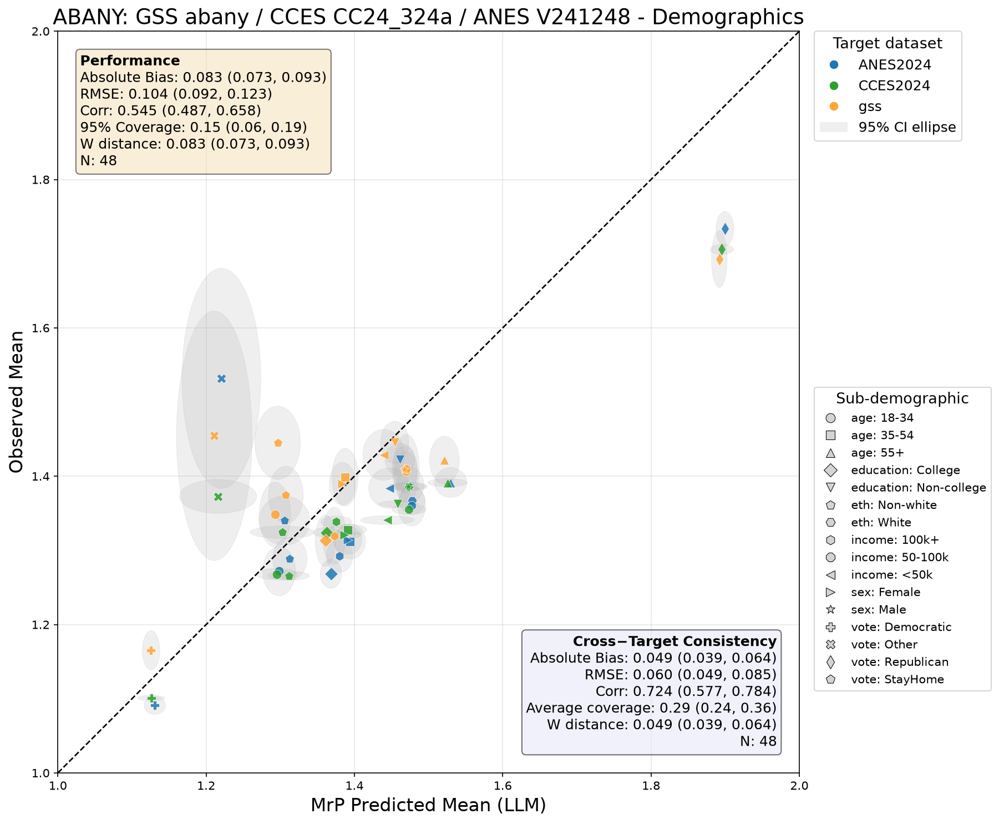

**ABANY: state plot**

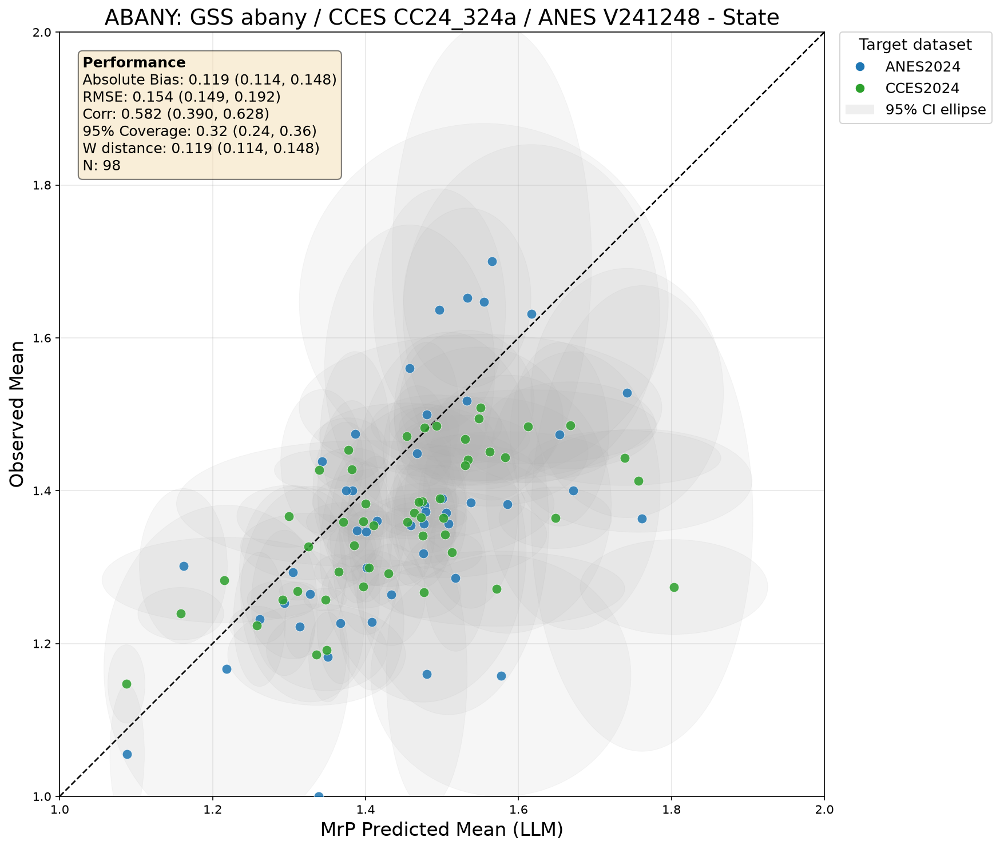

**AFFRMACT: demographics plot**

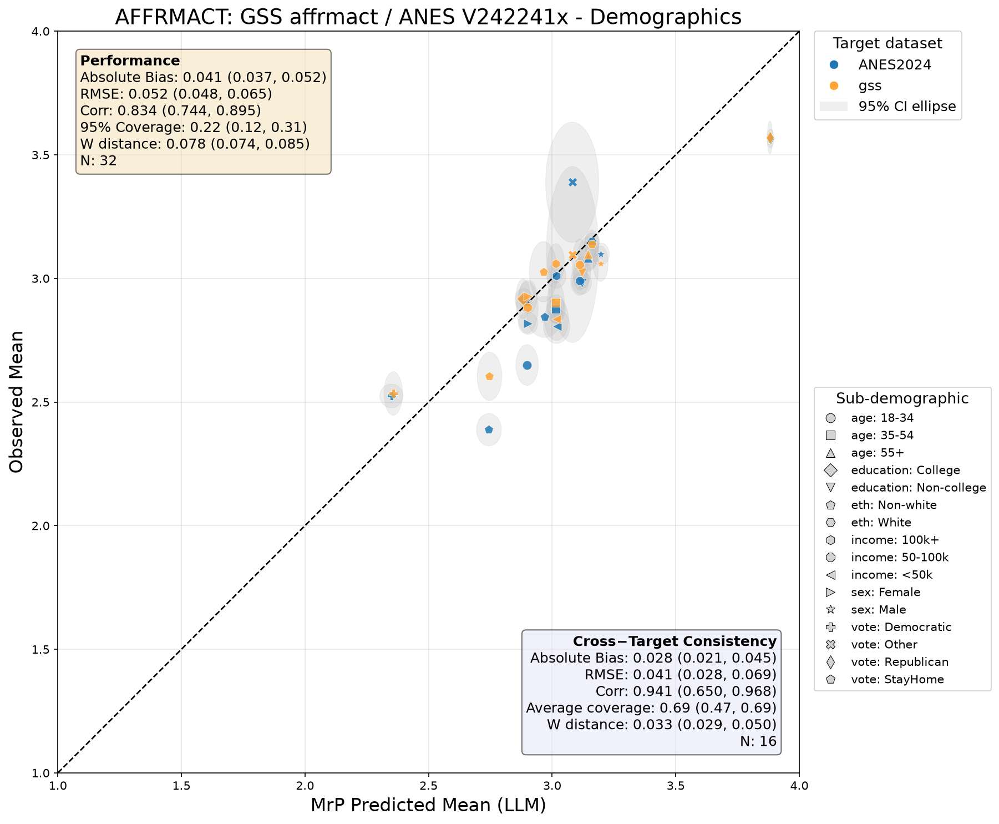

**AFFRMACT: state plot**

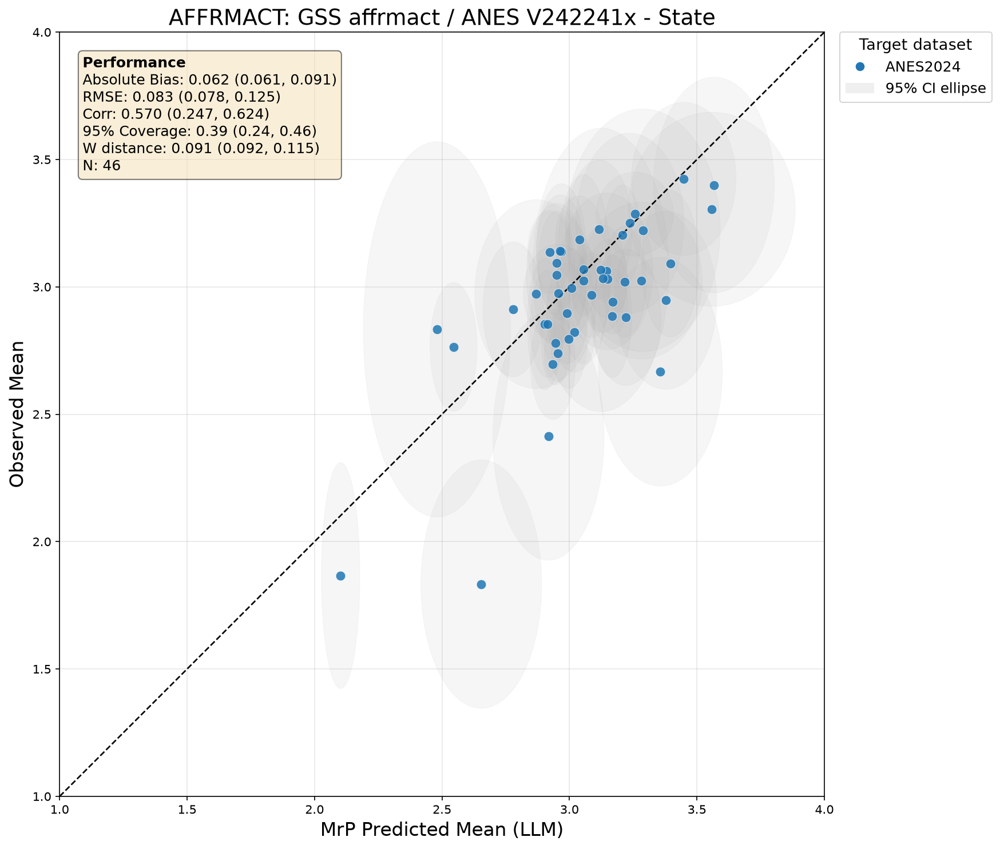

**BIASNEWS: demographics plot**

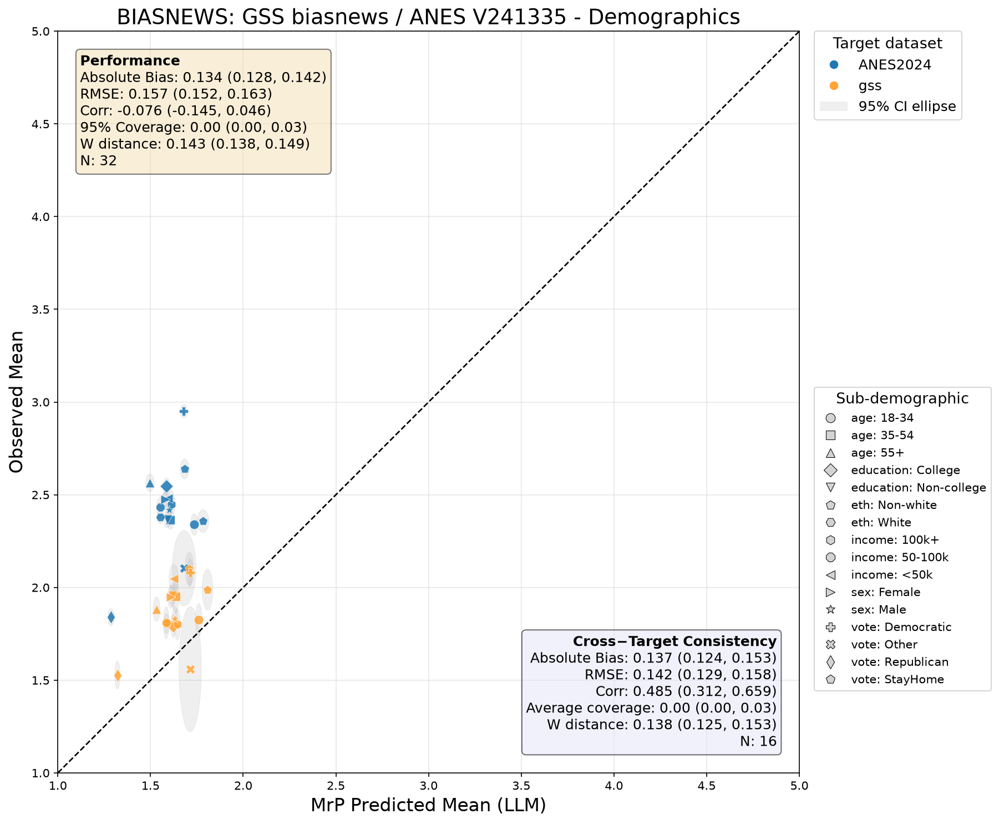

**BIASNEWS: state plot**

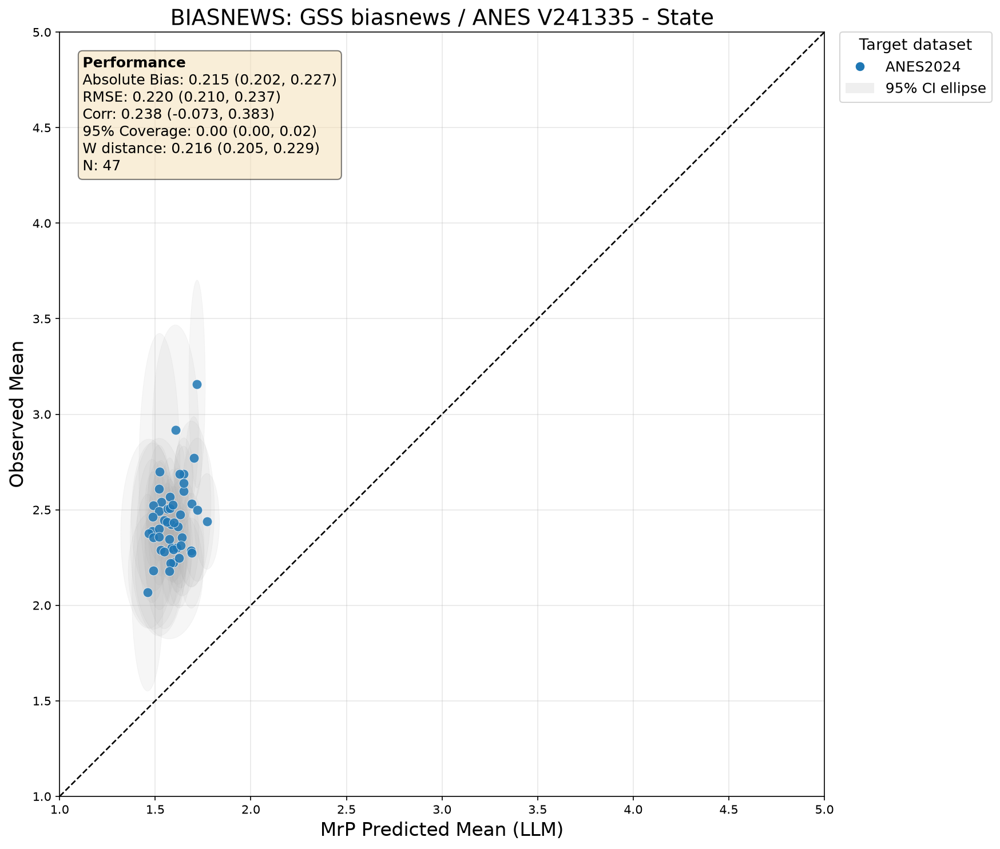

In [15]:
for belief_id in belief_ids[:3]:
    plot_dir = RUN_DIR / belief_id / 'plot'
    for name in ['demographics', 'state']:
        path = plot_dir / f'{belief_id}_{name}.png'
        if path.exists():
            display(Markdown(f'**{belief_id}: {name} plot**'))
            display(Image(filename=str(path)))

## Overall plots that include all belief questions (0-1 scale)

In [16]:
# Standardize observed/predicted means, quantiles and std columns to 0-1 using each question's 1..k scale
def standardize_plot_df(plot_df_input):
    out = plot_df_input.copy()
    denom = out['question_id'].map(lambda q: K_MAP[q] - 1).astype(float)
    for c in [c for c in out.columns if c.startswith('obs_') or c.startswith('pred_')]:
        if c.endswith('_sd'):
            out[c] = out[c].astype(float) / denom
        else:
            out[c] = (out[c].astype(float) - 1.0) / denom
    return out


# standardize draw level input: (x - 1) / (k - 1)
def standardize_draw_level_inputs(llm_draws_df_input, target_boot_df_input):
    llm_draws_std = llm_draws_df_input.copy()
    target_boot_std = target_boot_df_input.copy()
    denom_pred = llm_draws_std['question_id'].map(lambda q: float(K_MAP[q] - 1))
    denom_targ = target_boot_std['question_id'].map(lambda q: float(K_MAP[q] - 1))
    draw_cols = [c for c in llm_draws_std.columns if c not in set(KEY_COLS)]
    llm_draws_std[draw_cols] = (llm_draws_std[draw_cols].astype(float) - 1.0).div(denom_pred, axis=0)
    target_boot_std['obs_boot_mean'] = (target_boot_std['obs_boot_mean'].astype(float) - 1.0) / denom_targ
    return llm_draws_std, target_boot_std


standardized_plot_df = standardize_plot_df(plot_df)
llm_draws_std, target_boot_std = standardize_draw_level_inputs(llm_draws_df, target_boot_df)
all_dir = RUN_DIR / 'all_belief_plots'
national_dir = RUN_DIR / 'national_plots'
all_dir.mkdir(parents=True, exist_ok=True)
national_dir.mkdir(parents=True, exist_ok=True)

In [17]:
# build the overall plot for demo + state
demo_all = standardized_plot_df[~standardized_plot_df['grouping_var'].isin(['state', 'time_window_bin', 'national'])].copy()
state_all = standardized_plot_df[standardized_plot_df['grouping_var'] == 'state'].copy()

demo_perf = compute_metrics(demo_all, *subset_draws(demo_all, llm_draws_std, target_boot_std), y_range=1)
state_perf = compute_metrics(state_all, *subset_draws(state_all, llm_draws_std, target_boot_std), y_range=1)
demo_ceiling = compute_obs_pairwise_metrics(compute_obs_pairwise(demo_all), y_range=1, target_boot_input=target_boot_std)

for rows, perf, ceiling, is_state, name in [(demo_all, demo_perf, demo_ceiling, False, 'demographics'),
                                            (state_all, state_perf, None, True, 'state')]:
    fig, ax = plt.subplots(1, 1, figsize=(14, 10))
    plot_scatter_with_uncertainty_ellipses(ax, rows, metrics=perf, ci_level=95, question_id=None, benchmark=None,
                                           ceiling_metrics=ceiling, state=is_state, standardized_axis=True)
    fig.tight_layout(rect=[0, 0, 0.78, 1])
    path = all_dir / f'all_beliefs_{name}.png'
    fig.savefig(path, dpi=200, bbox_inches='tight')
    plt.close(fig)
    print('Saved:', path)
print('Demographic pooled performance:', demo_perf)
print('Demographic pooled ceiling:', demo_ceiling)
print('State pooled performance:', state_perf)

Saved: D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\mrp_7d\td10_ad08_w1000_s1000\all_belief_plots\all_beliefs_demographics.png
Saved: D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\mrp_7d\td10_ad08_w1000_s1000\all_belief_plots\all_beliefs_state.png
Demographic pooled performance: {'bias_mean': 0.1370479660237057, 'bias_ci': (0.13550388822867873, 0.13988520780389957), 'rmse_mean': 0.17381354367403676, 'rmse_ci': (0.1721551398820192, 0.17730657726613133), 'corr_mean': 0.6350941286740268, 'corr_ci': (0.6214117640710743, 0.6443421546122775), 'coverage_mean': 0.07654075546719682, 'coverage_ci': (0.06754473161033797, 0.08648111332007952), 'wdist_mean': 0.1575560099949617, 'wdist_ci': (0.1565473009865353, 0.16032505957238732), 'n_cells': 1006}
Demographic pooled ceiling: {'bias_mean': np.float64(0.07635918109530136), 'bias_ci': (0.07501776222384997, 0.0813067030328435), 'rmse_mean': np.float64(0.11143159948771011), 'rmse_ci': (0.1102107352608837, 0.11731800

**All beliefs: demographics plot**

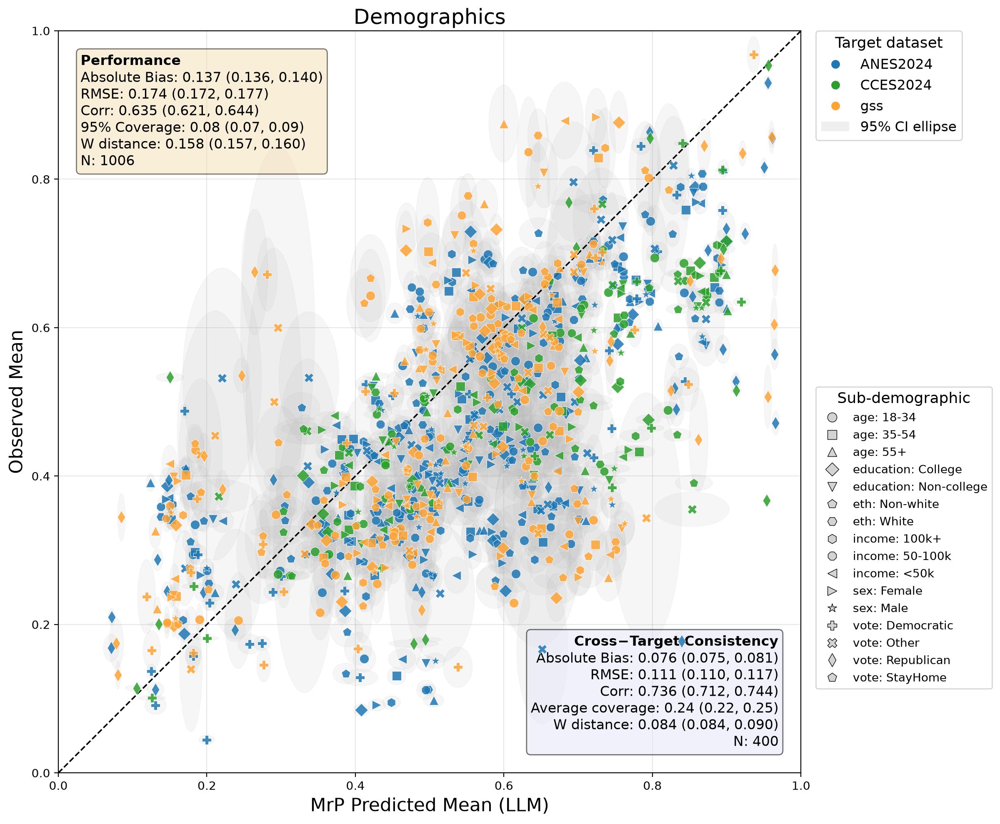

**All beliefs: state plot**

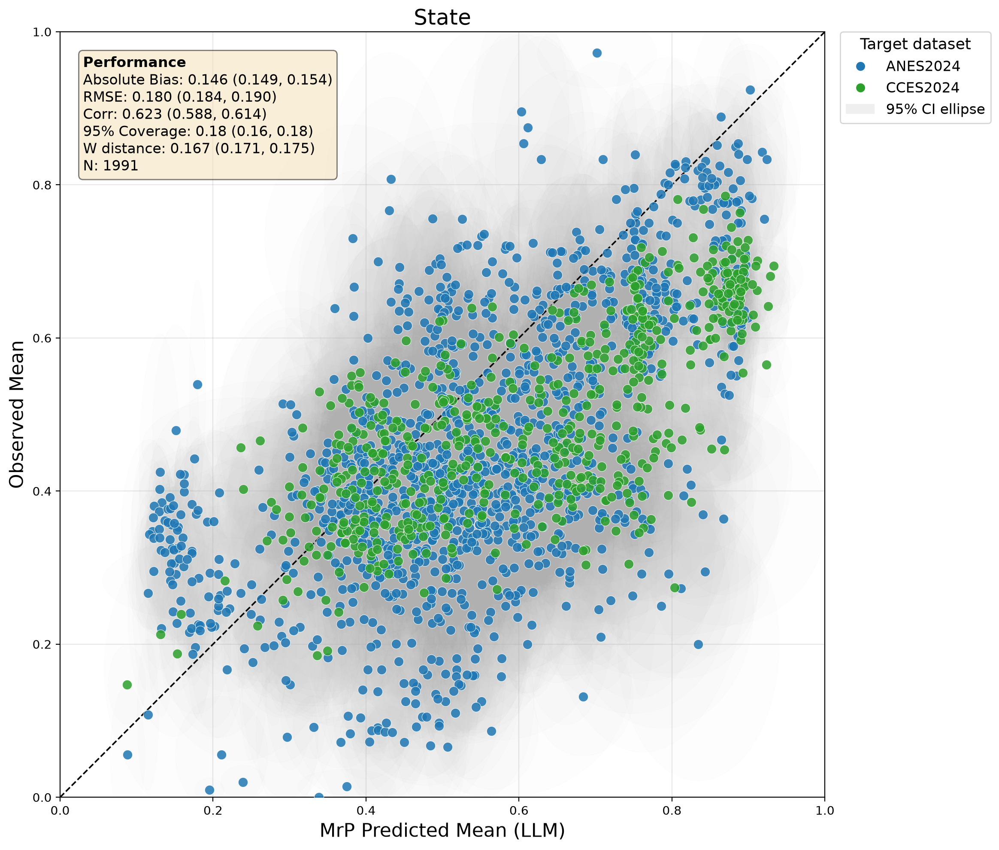

In [18]:
display(Markdown('**All beliefs: demographics plot**'))
display(Image(filename=str(all_dir / 'all_beliefs_demographics.png')))
display(Markdown('**All beliefs: state plot**'))
display(Image(filename=str(all_dir / 'all_beliefs_state.png')))

## National level plots

Each point is one belief x one week x one benchmark (weeks with at least `MIN_N_WINDOW` respondents).

Saved: D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\mrp_7d\td10_ad08_w1000_s1000\national_plots\national_time_window_scatter.png
National pooled performance: {'bias_mean': 0.1362579487603114, 'bias_ci': (0.13813649973493677, 0.14327569892352787), 'rmse_mean': 0.17424344585460538, 'rmse_ci': (0.17643850687361515, 0.18294267744027523), 'corr_mean': 0.4606087108336622, 'corr_ci': (0.4304346554480647, 0.47448745322901575), 'coverage_mean': 0.0823293172690763, 'coverage_ci': (0.05823293172690763, 0.08739959839357425), 'wdist_mean': 0.15704721236620828, 'wdist_ci': (0.15961575262972247, 0.16447478361131437), 'n_cells': 996}
National pooled ceiling: {'bias_mean': np.float64(0.0913720172080028), 'bias_ci': (0.09682460480678368, 0.10906447852284255), 'rmse_mean': np.float64(0.12426188753745913), 'rmse_ci': (0.12923029333485114, 0.14356849207170214), 'corr_mean': np.float64(0.5678567322766944), 'corr_ci': (0.4822410550868952, 0.575371797753512), 'cov_sym_mean': np.float64(0.43

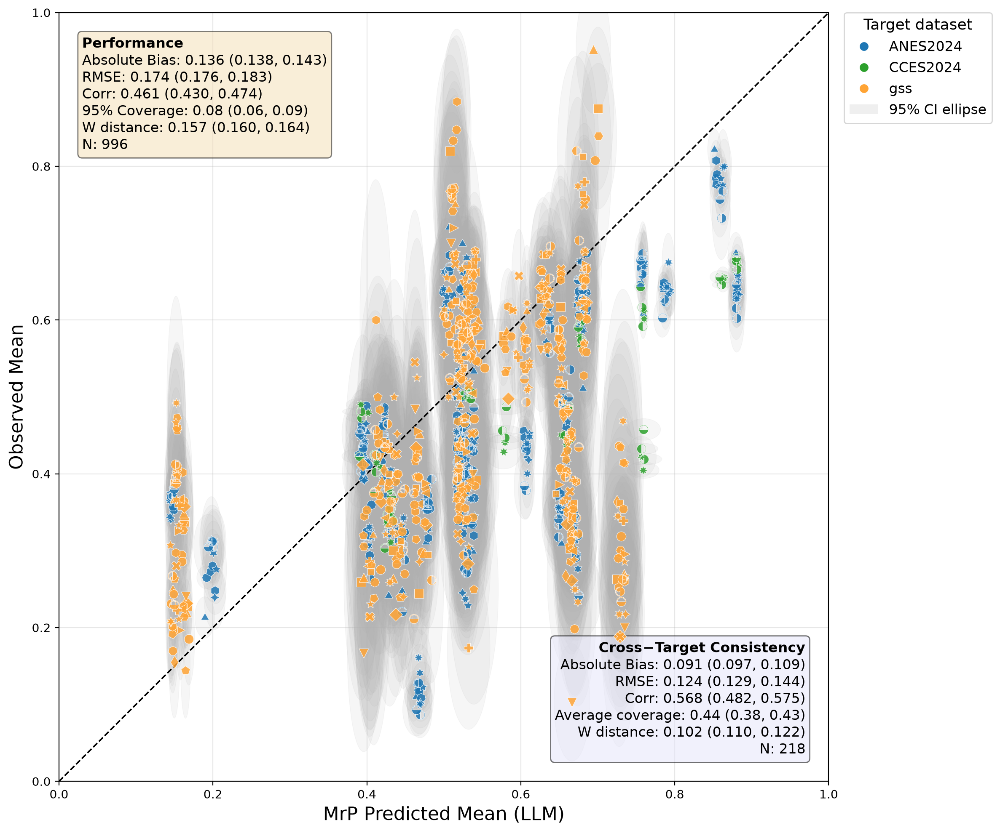

In [19]:
national_all = standardized_plot_df[standardized_plot_df['grouping_var'] == 'time_window_bin'].copy()
national_perf = compute_metrics(national_all, *subset_draws(national_all, llm_draws_std, target_boot_std), y_range=1)
national_ceiling = compute_obs_pairwise_metrics(compute_obs_pairwise(national_all), y_range=1, target_boot_input=target_boot_std)

fig, ax = plt.subplots(1, 1, figsize=(14, 10))
# 52 weekly markers would make the marker legend too long, so only the dataset legend is shown
plot_scatter_with_uncertainty_ellipses(ax, national_all, metrics=national_perf, ci_level=95, question_id=None,
                                       benchmark=None, ceiling_metrics=national_ceiling, state=None, national=True,
                                       show_legend=False, standardized_axis=True)
fig.tight_layout(rect=[0, 0, 0.78, 1])
path = national_dir / 'national_time_window_scatter.png'
fig.savefig(path, dpi=200, bbox_inches='tight')
plt.close(fig)
print('Saved:', path)
print('National pooled performance:', national_perf)
print('National pooled ceiling:', national_ceiling)
display(Image(filename=str(path)))

### National over-time trend for each belief

MrP line and 95% band over all 52 weeks; survey weekly means (95% bootstrap CI) where the survey has at least `MIN_N_WINDOW` respondents. Metrics are computed on the matched weeks (0-1 scale). Panels are sorted by correlation.

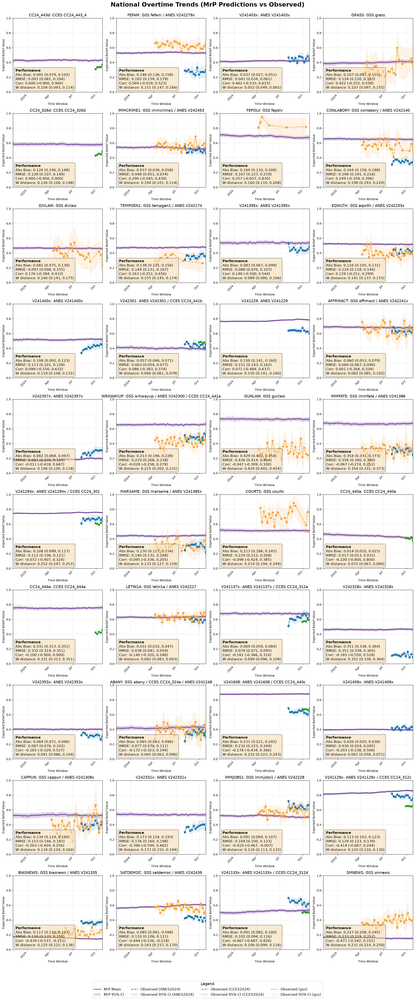

WindowsPath('D:/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/mrp_7d/td10_ad08_w1000_s1000/national_plots/national_overtime_trend.png')

In [20]:
national_series_std = national_series.copy()
denom = national_series_std['question_id'].map(lambda q: K_MAP[q] - 1)
for c in [c for c in national_series_std.columns if c.startswith('pred_')]:
    national_series_std[c] = national_series_std[c] / denom if c.endswith('_sd') else (national_series_std[c] - 1) / denom
national_series_std['time_dt'] = pd.to_datetime(national_series_std['window_start'])


def compute_question_metrics(question_id, plot_df_input, llm_draws_input, target_boot_input):
    work = plot_df_input[plot_df_input['question_id'] == question_id]
    if len(work) < 3:
        return None
    return compute_metrics(work, *subset_draws(work, llm_draws_input, target_boot_input), y_range=1)


def plot_national_overtime_grid(national_df, llm_draws_input, target_boot_input, ncols=4, save_dir=None):
    questions = sorted(national_series_std['question_id'].unique())
    metrics_by_qid = {qid: compute_question_metrics(qid, national_df, llm_draws_input, target_boot_input) for qid in questions}
    corr_order = sorted(questions, key=lambda q: (metrics_by_qid[q] is None,
                                                  -(metrics_by_qid[q]['corr_mean'] if metrics_by_qid[q] else 0)))
    mrp_color = '#6a3d9a'
    nrows = math.ceil(len(corr_order) / ncols)
    height = 4.6 * nrows + 2.0
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, height), squeeze=False)
    axes = axes.flatten()
    date_locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
    date_formatter = mdates.ConciseDateFormatter(date_locator)
    page_benchmarks = set()

    for ax, qid in zip(axes, corr_order):
        series = national_series_std[national_series_std['question_id'] == qid]
        ax.plot(series['time_dt'], series['pred_mean'], marker='o', markersize=3, linewidth=2.0, color=mrp_color)
        ax.fill_between(series['time_dt'], series['pred_lower_95'], series['pred_upper_95'], alpha=0.22, color=mrp_color)
        obs = national_df[national_df['question_id'] == qid].copy()
        obs['time_dt'] = pd.to_datetime(obs['category'].map(parse_time_window_start))
        for bench, s in obs.sort_values('time_dt').groupby('benchmark'):
            page_benchmarks.add(bench)
            color = DATASET_COLOR_MAP[bench]
            ax.plot(s['time_dt'], s['obs_mean'], marker='s', linewidth=2.0, color=color, linestyle='--', zorder=3)
            ax.fill_between(s['time_dt'], s['obs_lower_95'], s['obs_upper_95'], alpha=0.12, color=color, zorder=2)

        metrics = metrics_by_qid[qid]
        if metrics is not None:
            textstr = (
                f'$\\mathbf{{Performance}}$\n'
                f'Abs Bias: {metrics["bias_mean"]:.3f} '
                f'({metrics["bias_ci"][0]:.3f}, {metrics["bias_ci"][1]:.3f})\n'
                f'RMSE: {metrics["rmse_mean"]:.3f} '
                f'({metrics["rmse_ci"][0]:.3f}, {metrics["rmse_ci"][1]:.3f})\n'
                f'Corr: {metrics["corr_mean"]:.3f} '
                f'({metrics["corr_ci"][0]:.3f}, {metrics["corr_ci"][1]:.3f})\n'
                f'W distance: {metrics["wdist_mean"]:.3f} '
                f'({metrics["wdist_ci"][0]:.3f}, {metrics["wdist_ci"][1]:.3f})'
            )
        else:
            textstr = f'$\\mathbf{{Performance}}$\nFewer than 3 matched weeks'
        ax.text(0.03, 0.03, textstr, transform=ax.transAxes, fontsize=int(8 * FONT_SCALE), va='bottom', ha='left',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.6))
        ax.set_title(TITLES[qid], fontsize=int(9 * FONT_SCALE))
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Expected Belief Value')
        ax.set_ylim([0.0, 1.0])
        ax.set_xlim([national_series_std['time_dt'].min(), national_series_std['time_dt'].max()])
        ax.xaxis.set_major_locator(date_locator)
        ax.xaxis.set_major_formatter(date_formatter)
        ax.grid(True, alpha=0.3)
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    for ax in axes[len(corr_order):]:
        ax.axis('off')

    legend_handles = [Line2D([0], [0], color=mrp_color, lw=2, label='MrP Mean'),
                      Patch(facecolor=mrp_color, alpha=0.22, label='MrP 95% CI')]
    for bench in sorted(page_benchmarks):
        legend_handles.append(Line2D([0], [0], color=DATASET_COLOR_MAP[bench], lw=2, linestyle='--', label=f'Observed ({bench})'))
        legend_handles.append(Patch(facecolor=DATASET_COLOR_MAP[bench], alpha=0.12, label=f'Observed 95% CI ({bench})'))
    fig.legend(handles=legend_handles, title='Legend', fontsize=int(8 * FONT_SCALE), title_fontsize=int(9 * FONT_SCALE),
               loc='lower center', bbox_to_anchor=(0.5, 0.0), ncol=math.ceil(len(legend_handles) / 2), frameon=True)
    fig.tight_layout(rect=[0, 1.6 / height, 1, 1 - 0.6 / height])
    fig.suptitle('National Overtime Trends (MrP Predictions vs Observed)', fontsize=int(14 * FONT_SCALE),
                 fontweight='bold', y=1 - 0.2 / height)
    out_path = None
    if save_dir is not None:
        out_path = Path(save_dir) / 'national_overtime_trend.png'
        fig.savefig(out_path, dpi=200, bbox_inches='tight')
    plt.show()
    return out_path


plot_national_overtime_grid(national_all, llm_draws_std, target_boot_std, ncols=4, save_dir=national_dir)

### National: MrP pooled over the survey weeks vs the survey's overall mean

The 7-day counterpart of the biweekly "single time point vs pooled observations" plot: one point per belief x benchmark.

C:\Users\yuyue\AppData\Local\Temp\ipykernel_36092\3350604485.py:80: UserWarning: You passed an edgecolor/edgecolors ('white') for an unfilled marker ((5, 2, 0)).  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(grp['pred_mean'], grp['obs_mean'], color=DATASET_COLOR_MAP[str(ds)], marker=marker_map[sg],
C:\Users\yuyue\AppData\Local\Temp\ipykernel_36092\3350604485.py:80: UserWarning: You passed an edgecolor/edgecolors ('white') for an unfilled marker ((4, 2, 45)).  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(grp['pred_mean'], grp['obs_mean'], color=DATASET_COLOR_MAP[str(ds)], marker=marker_map[sg],
C:\Users\yuyue\AppData\Local\Temp\ipykernel_36092\3350604485.py:80: UserWarning: You passed an edgecolor/edgecolors ('white') for an unfilled marker ((8, 2, 0)).  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change 

Saved: D:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\mrp_7d\td10_ad08_w1000_s1000\national_plots\national_pooled_vs_obs.png
National pooled vs observed performance: {'bias_mean': 0.132641488917403, 'bias_ci': (0.1303463883217357, 0.13488566888756523), 'rmse_mean': 0.16368536815102708, 'rmse_ci': (0.16127207651289033, 0.16632253182384008), 'corr_mean': 0.5616839477726575, 'corr_ci': (0.5376200076804916, 0.581803235407066), 'coverage_mean': 0.031746031746031744, 'coverage_ci': (0.015873015873015872, 0.047619047619047616), 'wdist_mean': 0.15189065333773819, 'wdist_ci': (0.1498363653527964, 0.15415915374428002), 'n_cells': 63}


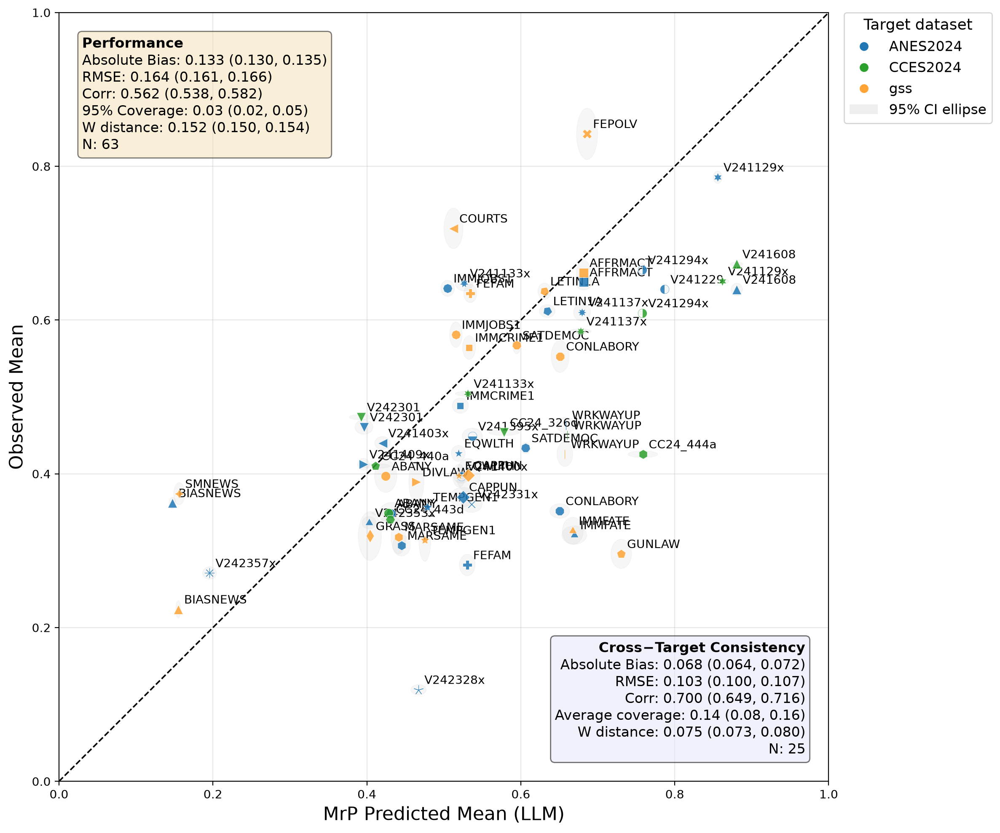

In [21]:
national_pooled = standardized_plot_df[standardized_plot_df['grouping_var'] == 'national'].copy()
pooled_perf = compute_metrics(national_pooled, *subset_draws(national_pooled, llm_draws_std, target_boot_std), y_range=1)
pooled_ceiling = compute_obs_pairwise_metrics(compute_obs_pairwise(national_pooled), y_range=1, target_boot_input=target_boot_std)
fig, ax = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(ax, national_pooled.assign(category=national_pooled['question_id'].map(ID_BY_QUESTION)),
                                       metrics=pooled_perf, ci_level=95, question_id=None, benchmark=None,
                                       ceiling_metrics=pooled_ceiling, state=None, national=True, show_legend=False,
                                       standardized_axis=True)
for _, row in national_pooled.iterrows():   # label each point with its belief id
    ax.annotate(ID_BY_QUESTION[row['question_id']], (row['pred_mean'], row['obs_mean']), xytext=(5, 5),
                textcoords='offset points', fontsize=int(7 * FONT_SCALE))
fig.tight_layout(rect=[0, 0, 0.78, 1])
path = national_dir / 'national_pooled_vs_obs.png'
fig.savefig(path, dpi=200, bbox_inches='tight')
plt.close(fig)
print('Saved:', path)
print('National pooled vs observed performance:', pooled_perf)
display(Image(filename=str(path)))

## National level time correlation analysis

In [22]:
# Spearman correlation between the weekly MrP and survey means, per question and benchmark
records = []
for (qid, bench), grp in national_all.groupby(['question_id', 'benchmark']):
    corr = stats.spearmanr(grp['pred_mean'], grp['obs_mean'])[0] if len(grp) >= 3 else np.nan
    records.append({'belief': ID_BY_QUESTION[qid], 'benchmark': bench, 'n_time_bins': len(grp), 'spearman_corr': corr,
                    'mean_abs_diff_0_1': np.mean(np.abs(grp['pred_mean'] - grp['obs_mean']))})
corr_by_question = pd.DataFrame(records).sort_values('spearman_corr', ascending=False)
corr_by_question.to_csv(national_dir / 'national_time_correlation.csv', index=False)
print('Overall Spearman correlation:', stats.spearmanr(national_all['pred_mean'], national_all['obs_mean'])[0])
corr_by_question

Overall Spearman correlation: 0.4606087108336622


,belief,benchmark,n_time_bins,spearman_corr,mean_abs_diff_0_1
11,CC24_443d,CCES2024,5,0.600000,0.090894
1,ABANY,CCES2024,5,0.500000,0.082420
20,FEFAM,gss,30,0.463233,0.099376
50,V241403x,ANES2024,13,0.461538,0.036524
22,GRASS,gss,24,0.422450,0.107172
...,...,...,...,...,...
57,V242331x,ANES2024,13,-0.395604,0.173329
36,SMNEWS,gss,29,-0.470559,0.227329
26,IMMFATE,ANES2024,13,-0.510989,0.362417
47,V241294x,CCES2024,5,-0.600000,0.144903
